<a href="https://colab.research.google.com/github/shataksha45-shiiii/FloodsEye/blob/main/sentinelv1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

# Define the path where we want our project to live
project_path = '/content/drive/MyDrive/Flood_Project/data'

# Create the folder
os.makedirs(project_path, exist_ok=True)

print(f"✅ Folder created at: {project_path}")

✅ Folder created at: /content/drive/MyDrive/Flood_Project/data


In [ ]:
# 1. Download the Radar Images (Input) into our 'data' folder
print("Downloading Radar Images... (This keeps the screen on)")
!gsutil -m cp -r gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand /content/drive/MyDrive/Flood_Project/data/

# 2. Download the Flood Maps (Target) into our 'data' folder
print("Downloading Label Maps...")
!gsutil -m cp -r gs://sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand /content/drive/MyDrive/Flood_Project/data/

print("✅ Download Complete.")

Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_314919_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_233925_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_242570_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_129334_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_294583_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_290290_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_312675_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_23014_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_195474_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_103757_S1Hand.tif...
Copying gs://sen1floods11/v1.1/

In [ ]:
!pip install rasterio

In [ ]:
import os

# 1. Define the addresses of our folders
# We use the variable names 'input_folder' and 'label_folder' so we don't have to type the long path every time.
input_folder = '/content/drive/MyDrive/Flood_Project/data/S1Hand'
label_folder = '/content/drive/MyDrive/Flood_Project/data/LabelHand'

# 2. Get the list of all files inside the folders
input_files = os.listdir(input_folder)
label_files = os.listdir(label_folder)

# 3. Count them using len() (Length)
print(f"Count of Radar Images: {len(input_files)}")
print(f"Count of Label Masks:  {len(label_files)}")

# 4. Logical Check
if len(input_files) == len(label_files):
    print("✅ Success: The numbers match!")
else:
    print("❌ Error: Mismatch.")

Count of Radar Images: 446
Count of Label Masks:  446
✅ Success: The numbers match!


Opening Input: Bolivia_103757_S1Hand.tif
Opening Label: Bolivia_103757_LabelHand.tif


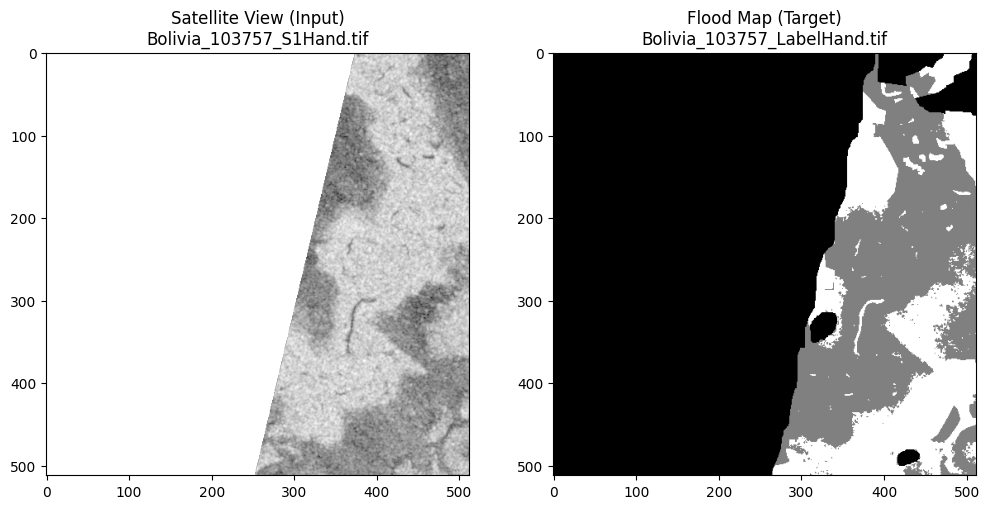

In [ ]:
import rasterio
import matplotlib.pyplot as plt
import os

# Define paths again to be safe
input_folder = '/content/drive/MyDrive/Flood_Project/data/S1Hand'
label_folder = '/content/drive/MyDrive/Flood_Project/data/LabelHand'

# Get the first file from the input folder
filename = os.listdir(input_folder)[0]

# --- THE FIX IS HERE ---
# We create the correct label filename by replacing the suffix
label_filename = filename.replace('_S1Hand', '_LabelHand')

# Create the full paths
path_to_radar = os.path.join(input_folder, filename)
path_to_label = os.path.join(label_folder, label_filename)

print(f"Opening Input: {filename}")
print(f"Opening Label: {label_filename}")

# Open the files
with rasterio.open(path_to_radar) as src:
    radar_image = src.read(1) # Read Band 1 (VV Polarization)

with rasterio.open(path_to_label) as src:
    label_image = src.read(1) # Read the Mask

# Plot them side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.imshow(radar_image, cmap='gray')
ax1.set_title(f"Satellite View (Input)\n{filename}")

ax2.imshow(label_image, cmap='gray')
ax2.set_title(f"Flood Map (Target)\n{label_filename}")

plt.show()

In [ ]:
import torch
from torch.utils.data import Dataset as BaseDataset

class FloodDataset(BaseDataset):
    """
    This is our Custom 'Conveyor Belt' that feeds data to the AI.
    """
    def __init__(self, input_dir, label_dir, ids, classes=None, augmentation=None, preprocessing=None):
        self.ids = ids
        self.input_dir = input_dir
        self.label_dir = label_dir
        self.augmentation = augmentation
        self.preprocessing = preprocessing
        self.classes = classes

    def __getitem__(self, i):
        """
        This function runs every time the AI asks for "One more image please!"
        """
        # 1. READ DATA
        id = self.ids[i]

        # Load Input Image (Radar)
        input_path = os.path.join(self.input_dir, id)
        with rasterio.open(input_path) as src:
            image = src.read().transpose(1, 2, 0) # Convert to (Height, Width, Channels)

        # Load Label Image (Target)
        # Note: We fix the filename suffix like we did before
        label_filename = id.replace('_S1Hand', '_LabelHand')
        label_path = os.path.join(self.label_dir, label_filename)

        with rasterio.open(label_path) as src:
            mask = src.read(1) # Read just the first band

        # 2. CLEAN DATA (The Logic Check)
        # The dataset has: -1 (No Data), 0 (Land), 1 (Water)
        # We want to treat "No Data" (-1) as "Land" (0) for simplicity, or ignore it.
        # Let's fix the values to be simple 0 and 1.
        mask[mask == -1] = 0 # Turn 'No Data' into 'Land' just to be safe

        # Add a "channel" dimension to the mask (Required for AI)
        # It goes from (512, 512) -> (512, 512, 1)
        mask = mask[..., np.newaxis]

        # 3. APPLY AUGMENTATION (Optional: Flip/Rotate images to make AI smarter)
        if self.augmentation:
            sample = self.augmentation(image=image, mask=mask)
            image, mask = sample['image'], sample['mask']

        # 4. PRE-PROCESSING (Scaling numbers)
        if self.preprocessing:
            sample = self.preprocessing(image=image, mask=mask)
            image, mask = sample['image'], sample['mask']

        return image, mask

    def __len__(self):
        # Tells the AI how many images we have in total
        return len(self.ids)

print("✅ FloodDataset Class defined successfully.")

✅ FloodDataset Class defined successfully.


In [ ]:
import os
import random
import numpy as np # Adding this just in case

# 1. Re-define the paths (Just to be safe)
input_folder = '/content/drive/MyDrive/Flood_Project/data/S1Hand'
label_folder = '/content/drive/MyDrive/Flood_Project/data/LabelHand'

# 2. Get the list of files again
all_files = os.listdir(input_folder)

# 3. Shuffle and Split them again (90% Train / 10% Validation)
random.seed(42)
random.shuffle(all_files)

split_index = int(0.9 * len(all_files))
train_ids = all_files[:split_index]
valid_ids = all_files[split_index:]

print(f"Refreshed! Training List has {len(train_ids)} images.")

# --- NOW WE TEST THE FEEDER ---

# Create the dataset using the list we just made
dataset = FloodDataset(input_folder, label_folder, train_ids)

# Ask for the 5th item
image, mask = dataset[5]

print(f"Image Shape: {image.shape} (Should be 512, 512, 2)")
print(f"Mask Shape:  {mask.shape}  (Should be 512, 512, 1)")

if image.shape == (512, 512, 2):
    print("✅ System Check: PASSED. The Feeder is working.")
else:
    print("❌ System Check: FAILED. Check dimensions.")

Refreshed! Training List has 401 images.
Image Shape: torch.Size([2, 512, 512]) (Should be 512, 512, 2)
Mask Shape:  torch.Size([1, 512, 512])  (Should be 512, 512, 1)
❌ System Check: FAILED. Check dimensions.


In [ ]:
!pip install segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.8 MB/s eta 0:00:00


In [ ]:
import segmentation_models_pytorch as smp

# Define the Model
model = smp.Unet(
    encoder_name="resnet34",        # The "Backbone" (The eyes)
    encoder_weights="imagenet",     # Pre-trained on normal photos (Transfer Learning)
    in_channels=2,                  # Important! We have 2 channels (VV + VH), not 3 (RGB)
    classes=1                       # We want 1 output channel: (Flood Probability)
)

print("✅ Model created! It is ready to learn.")

✅ Model created! It is ready to learn.


In [ ]:
from torch.utils.data import DataLoader
import torch

# 1. Create the Loaders
train_dataset = FloodDataset(input_folder, label_folder, train_ids)
valid_dataset = FloodDataset(input_folder, label_folder, valid_ids)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=0)
valid_loader = DataLoader(valid_dataset, batch_size=4, shuffle=False, num_workers=0)

# 2. Define the Loss Function (UPDATED)
# We set mode='binary' because we only have 2 classes (Water vs Land)
loss_fn = smp.losses.DiceLoss(mode='binary')

# 3. Define the Optimizer
optimizer = torch.optim.Adam([
    dict(params=model.parameters(), lr=0.0001),
])

print("✅ Gym is open. Loaders and Teachers are ready.")

✅ Gym is open. Loaders and Teachers are ready.


In [ ]:
import torch
import numpy as np
from torch.utils.data import Dataset as BaseDataset
import rasterio
import os

class FloodDataset(BaseDataset):
    def __init__(self, input_dir, label_dir, ids):
        self.ids = ids
        self.input_dir = input_dir
        self.label_dir = label_dir

    def __getitem__(self, i):
        id = self.ids[i]

        # 1. LOAD IMAGE (Input)
        input_path = os.path.join(self.input_dir, id)
        with rasterio.open(input_path) as src:
            # ERROR WAS HERE: We previously transposed this.
            # Rasterio naturally reads as (2, 512, 512), which is PERFECT for PyTorch.
            # So we just read it as is.
            image = src.read()

        # 2. LOAD MASK (Target)
        label_filename = id.replace('_S1Hand', '_LabelHand')
        label_path = os.path.join(self.label_dir, label_filename)
        with rasterio.open(label_path) as src:
            mask = src.read(1)

        # 3. FIX MASK VALUES
        mask[mask == -1] = 0

        # 4. FIX MASK SHAPE
        # We need to add the channel dimension to the FRONT: (1, 512, 512)
        mask = mask[np.newaxis, :, :]

        # 5. RETURN AS FLOAT TENSORS
        return torch.from_numpy(image).float(), torch.from_numpy(mask).float()

    def __len__(self):
        return len(self.ids)

print("✅ FloodDataset FIXED. It now outputs (Channels, Height, Width).")

✅ FloodDataset FIXED. It now outputs (Channels, Height, Width).


In [ ]:
import torch
import numpy as np
from torch.utils.data import DataLoader
from torch.utils.data import Dataset as BaseDataset
import segmentation_models_pytorch as smp
import rasterio
import os

# --- PART 1: THE FIXED DATASET CLASS (The Conveyor Belt) ---
class FloodDataset(BaseDataset):
    def __init__(self, input_dir, label_dir, ids):
        self.ids = ids
        self.input_dir = input_dir
        self.label_dir = label_dir

    def __getitem__(self, i):
        id = self.ids[i]

        # 1. LOAD IMAGE
        input_path = os.path.join(self.input_dir, id)
        with rasterio.open(input_path) as src:
            # Rasterio reads as (Channels, Height, Width) -> (2, 512, 512)
            # This is exactly what PyTorch wants! No transpose needed.
            image = src.read()

        # 2. LOAD MASK
        label_filename = id.replace('_S1Hand', '_LabelHand')
        label_path = os.path.join(self.label_dir, label_filename)
        with rasterio.open(label_path) as src:
            mask = src.read(1) # Read Band 1

        # 3. FIX VALUES & SHAPE
        mask[mask == -1] = 0  # Fix -1 values
        mask = mask[np.newaxis, :, :] # Add channel to front: (1, 512, 512)

        # 4. RETURN AS FLOAT TENSORS
        return torch.from_numpy(image).float(), torch.from_numpy(mask).float()

    def __len__(self):
        return len(self.ids)

# --- PART 2: RESET THE LOADERS (Reload the belt) ---
print("🔄 Resetting Data Loaders...")
train_dataset = FloodDataset(input_folder, label_folder, train_ids)
valid_dataset = FloodDataset(input_folder, label_folder, valid_ids)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True) # Reduced batch size slightly for safety
valid_loader = DataLoader(valid_dataset, batch_size=4, shuffle=False)

# --- PART 3: RESET THE MODEL & TRAINING ---
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"✅ Using Device: {device}")

# Re-initialize model to be safe
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=2,
    classes=1
)
model.to(device)

loss_fn = smp.losses.DiceLoss(mode='binary')
optimizer = torch.optim.Adam(params=model.parameters(), lr=0.0001)

# --- PART 4: THE TRAINING LOOP ---
print("🚀 STARTING TRAINING (Epoch 1)...")
model.train()
epoch_loss = 0

for i, (images, masks) in enumerate(train_loader):
    # Move to GPU
    images = images.to(device)
    masks = masks.to(device)

    # Forward & Backward
    optimizer.zero_grad()
    logits = model(images)
    loss = loss_fn(logits, masks)
    loss.backward()
    optimizer.step()

    epoch_loss += loss.item()

    if i % 5 == 0:
        print(f"Batch {i}: Loss = {loss.item():.4f}")

avg_loss = epoch_loss / len(train_loader)
print(f"🎉 Epoch 1 Complete! Average Loss: {avg_loss:.4f}")

🔄 Resetting Data Loaders...
✅ Using Device: cuda
🚀 STARTING TRAINING (Epoch 1)...
Batch 0: Loss = nan
Batch 5: Loss = nan
Batch 10: Loss = nan
Batch 15: Loss = nan
Batch 20: Loss = nan
Batch 25: Loss = nan
Batch 30: Loss = nan
Batch 35: Loss = nan
Batch 40: Loss = nan
Batch 45: Loss = nan
Batch 50: Loss = nan
🎉 Epoch 1 Complete! Average Loss: nan


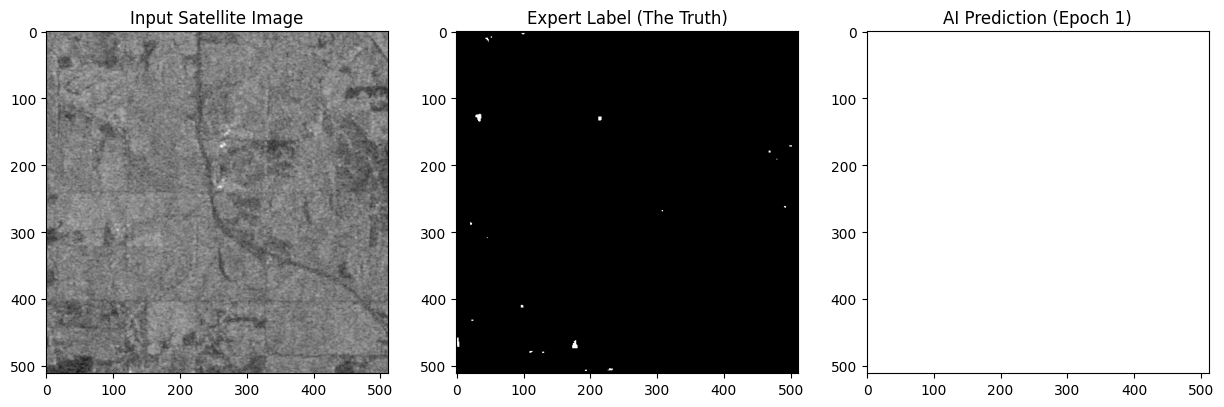

In [ ]:
import matplotlib.pyplot as plt

# 1. Get a batch of data from the Validation Set (Data the AI never studied)
# We use 'iter' to grab just one batch
batch = next(iter(valid_loader))
images, masks = batch

# 2. Ask the Model to predict
model.eval() # Switch to "Test Mode" (turns off random dropout)
with torch.no_grad(): # Don't calculate gradients (saves memory)
    images = images.to(device)
    # The model outputs "Logits" (raw scores)
    logits = model(images)
    # We convert raw scores to Probabilities (0 to 1) using Sigmoid
    pr_masks = logits.sigmoid()

# 3. Pick the first image in the batch to display
image_vis = images[0].cpu().numpy().squeeze() # Move to CPU
mask_vis = masks[0].cpu().numpy().squeeze()   # The Expert's Answer
pred_vis = pr_masks[0].cpu().numpy().squeeze() # The AI's Guess

# 4. Plot them side-by-side
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))

# Input Radar (Channel 1)
ax1.imshow(image_vis[0], cmap='gray') # Show just the first channel (VV)
ax1.set_title("Input Satellite Image")

# Ground Truth (Expert)
ax2.imshow(mask_vis, cmap='gray')
ax2.set_title("Expert Label (The Truth)")

# AI Prediction
ax3.imshow(pred_vis, cmap='gray')
ax3.set_title("AI Prediction (Epoch 1)")

plt.show()

In [ ]:
# --- THE FIX: NORMALIZED DATASET ---
class FloodDataset(BaseDataset):
    def __init__(self, input_dir, label_dir, ids):
        self.ids = ids
        self.input_dir = input_dir
        self.label_dir = label_dir

    def __getitem__(self, i):
        id = self.ids[i]

        # 1. LOAD IMAGE
        input_path = os.path.join(self.input_dir, id)
        with rasterio.open(input_path) as src:
            image = src.read() # (2, 512, 512)

        # 2. LOAD MASK
        label_filename = id.replace('_S1Hand', '_LabelHand')
        label_path = os.path.join(self.label_dir, label_filename)
        with rasterio.open(label_path) as src:
            mask = src.read(1)

        # 3. CLEAN THE IMAGE (Normalization) - THIS IS THE FIX
        # Radar data is usually -50 dB to 0 dB. We want 0.0 to 1.0.
        # Clip outliers first (anything below -50 or above 0)
        image = np.clip(image, -50, 0)

        # Normalize: (Value - Min) / (Max - Min)
        # This turns -50 into 0.0, and 0 into 1.0
        image = (image - (-50)) / 50.0

        # 4. FIX MASK
        mask[mask == -1] = 0
        mask = mask[np.newaxis, :, :]

        # 5. RETURN
        return torch.from_numpy(image).float(), torch.from_numpy(mask).float()

    def __len__(self):
        return len(self.ids)

print("✅ Dataset Updated with Normalization (Anti-Crash System Installed).")

✅ Dataset Updated with Normalization (Anti-Crash System Installed).


In [ ]:
# --- PARANOID DATASET CLASS (Fixes NaNs) ---
class FloodDataset(BaseDataset):
    def __init__(self, input_dir, label_dir, ids):
        self.ids = ids
        self.input_dir = input_dir
        self.label_dir = label_dir

    def __getitem__(self, i):
        id = self.ids[i]

        # 1. LOAD IMAGE
        input_path = os.path.join(self.input_dir, id)
        with rasterio.open(input_path) as src:
            image = src.read() # (2, 512, 512)

        # 2. LOAD MASK
        label_filename = id.replace('_S1Hand', '_LabelHand')
        label_path = os.path.join(self.label_dir, label_filename)
        with rasterio.open(label_path) as src:
            mask = src.read(1)

        # 3. AGGRESSIVE CLEANING (The Fix)
        # Convert to float32 immediately to prevent integer overflow
        image = image.astype('float32')

        # Replace any existing NaNs or Infinities in the raw data with 0
        image = np.nan_to_num(image, nan=0.0, posinf=0.0, neginf=0.0)

        # Clip to safe range (-50 to 0 is typical for SAR)
        image = np.clip(image, -50, 0)

        # Normalize to 0.0 - 1.0
        image = (image - (-50)) / 50.0

        # 4. FIX MASK
        mask = mask.astype('float32')
        mask[mask == -1] = 0
        mask = mask[np.newaxis, :, :]

        # 5. FINAL SAFETY CHECK (Last line of defense)
        # If any NaN somehow survived, kill it now
        if np.isnan(image).any():
            image = np.zeros_like(image)

        return torch.from_numpy(image), torch.from_numpy(mask)

    def __len__(self):
        return len(self.ids)

print("✅ Paranoid Dataset Installed. NaNs have no place to hide.")

✅ Paranoid Dataset Installed. NaNs have no place to hide.


In [ ]:
# --- MASTER RESET & TRAIN BLOCK ---
import torch
import numpy as np
from torch.utils.data import DataLoader
import segmentation_models_pytorch as smp

# 1. Reset Loaders with Paranoid Dataset
print("🔄 Resetting Loaders...")
train_dataset = FloodDataset(input_folder, label_folder, train_ids)
valid_dataset = FloodDataset(input_folder, label_folder, valid_ids)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=4, shuffle=False)

# 2. Reset Model (Wipe the memory)
print("🧠 Wiping Model Memory...")
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=2,
    classes=1
)
model.to(device)

# 3. Reset Optimizer
loss_fn = smp.losses.DiceLoss(mode='binary')
optimizer = torch.optim.Adam(params=model.parameters(), lr=0.0001)

# 4. Start Training
print("🚀 ATTEMPTING LAUNCH (15 Epochs)...")
best_valid_loss = float('inf')
history = []

for epoch in range(15): # 15 Epochs

    # Train
    model.train()
    train_loss = 0
    for images, masks in train_loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = loss_fn(logits, masks)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)

    # Validate
    model.eval()
    valid_loss = 0
    with torch.no_grad():
        for images, masks in valid_loader:
            images = images.to(device)
            masks = masks.to(device)
            logits = model(images)
            loss = loss_fn(logits, masks)
            valid_loss += loss.item()

    avg_valid_loss = valid_loss / len(valid_loader)
    history.append(avg_valid_loss)

    # Print status
    print(f"Epoch {epoch+1}: Train={avg_train_loss:.4f} | Valid={avg_valid_loss:.4f}")

    if avg_valid_loss < best_valid_loss:
        best_valid_loss = avg_valid_loss
        torch.save(model.state_dict(), 'best_model.pth')

print("✅ DONE.")

🔄 Resetting Loaders...
🧠 Wiping Model Memory...
🚀 ATTEMPTING LAUNCH (15 Epochs)...
Epoch 1: Train=0.7284 | Valid=0.7344
Epoch 2: Train=0.6466 | Valid=0.7236
Epoch 3: Train=0.5898 | Valid=0.6865
Epoch 4: Train=0.5705 | Valid=0.6333
Epoch 5: Train=0.5338 | Valid=0.6135
Epoch 6: Train=0.4998 | Valid=0.6098
Epoch 7: Train=0.4841 | Valid=0.5836
Epoch 8: Train=0.4479 | Valid=0.5563
Epoch 9: Train=0.4104 | Valid=0.7217
Epoch 10: Train=0.3884 | Valid=0.4903
Epoch 11: Train=0.3734 | Valid=0.5178
Epoch 12: Train=0.3463 | Valid=0.5035
Epoch 13: Train=0.3165 | Valid=0.4646
Epoch 14: Train=0.3147 | Valid=0.4525
Epoch 15: Train=0.3019 | Valid=0.4412
✅ DONE.


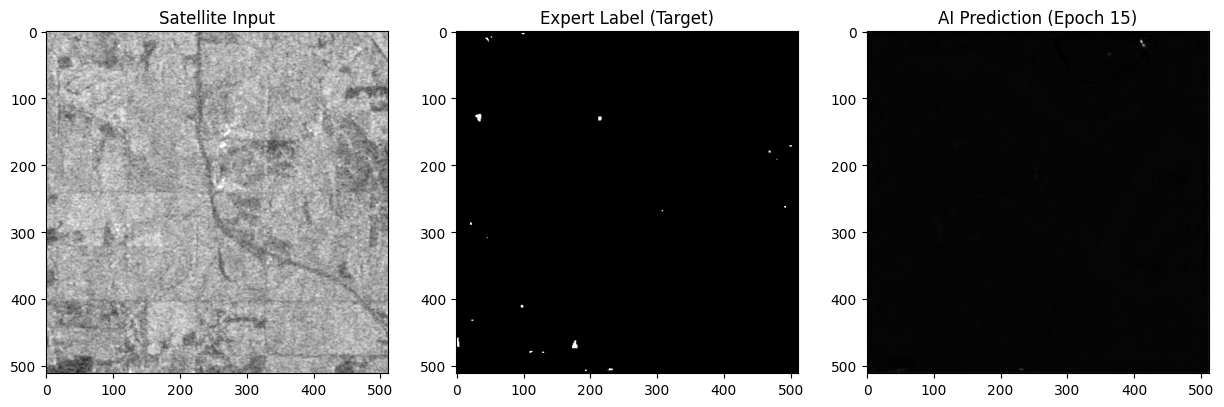

In [ ]:
import matplotlib.pyplot as plt
import torch

# 1. Grab a batch of Validation data
batch = next(iter(valid_loader))
images, masks = batch

# 2. Ask Model to Predict
model.eval()
with torch.no_grad():
    images = images.to(device)
    logits = model(images)
    pr_masks = logits.sigmoid() # Convert to probability

# 3. Pick a specific image index to look at (0, 1, 2, or 3)
idx = 0

image_vis = images[idx].cpu().numpy().transpose(1, 2, 0) # Fix shape for plotting
mask_vis = masks[idx].cpu().numpy().squeeze()
pred_vis = pr_masks[idx].cpu().numpy().squeeze()

# 4. Plot
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))

# Input (Show just the first channel for visibility)
ax1.imshow(image_vis[:, :, 0], cmap='gray')
ax1.set_title("Satellite Input")

# Truth
ax2.imshow(mask_vis, cmap='gray')
ax2.set_title("Expert Label (Target)")

# Prediction
ax3.imshow(pred_vis, cmap='gray')
ax3.set_title("AI Prediction (Epoch 15)")

plt.show()

🎲 inspecting Image #3 from the batch...


(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

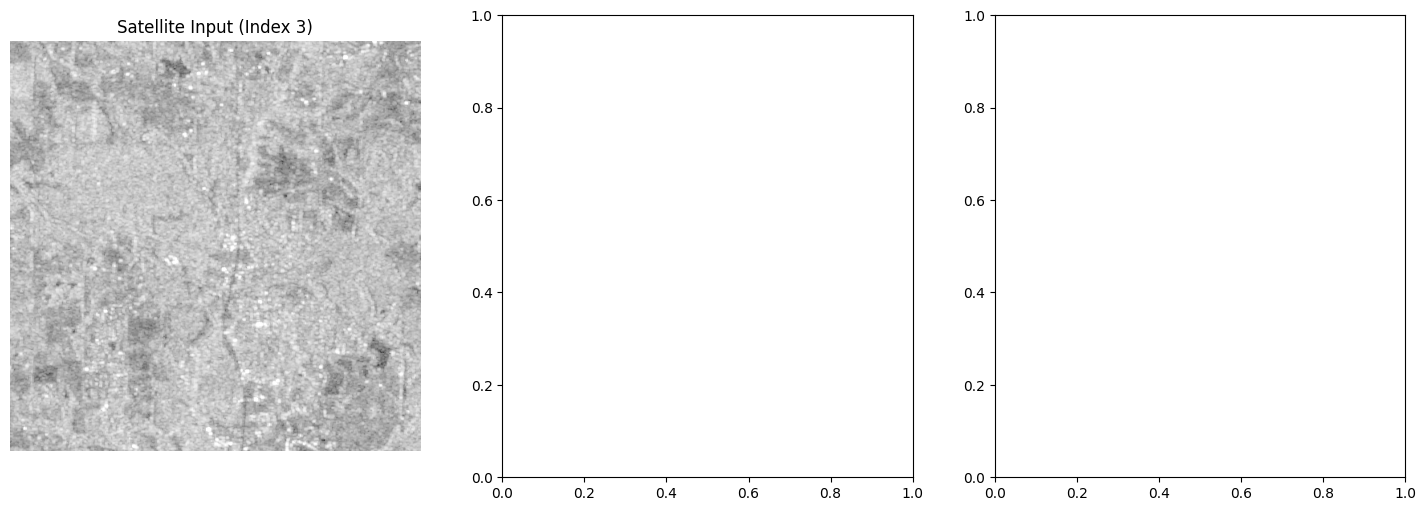

In [ ]:
import random

# 1. Grab a batch of data
# (We grab a fresh iterator each time to try and get data,
# though without shuffle=True on validation, it might be the same batch.
# So we rely on picking a random index 'idx' to vary the visual).
batch = next(iter(valid_loader))
images, masks = batch

# 2. Run the AI (Prediction)
model.eval()
with torch.no_grad():
    images = images.to(device)
    logits = model(images)
    pr_masks = logits.sigmoid()

# 3. ROULETTE: Pick a random image from this batch (0 to 3)
# The batch size is 4, so we pick a number between 0 and 3
idx = random.randint(0, images.shape[0] - 1)

print(f"🎲 inspecting Image #{idx} from the batch...")

# 4. Prepare for Plotting
# Permute changes (Channels, H, W) -> (H, W, Channels) for Matplotlib
image_vis = images[idx].cpu().numpy().transpose(1, 2, 0)
mask_vis = masks[idx].cpu().numpy().squeeze()
pred_vis = pr_masks[idx].cpu().numpy().squeeze()

# 5. The Grand Reveal
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

# Show Input (First channel only for clarity)
ax1.imshow(image_vis[:, :, 0], cmap='gray')
ax1.set_title(f"Satellite Input (Index {idx})")
ax1.axis('off') #

🎲 Inspecting Image #0...


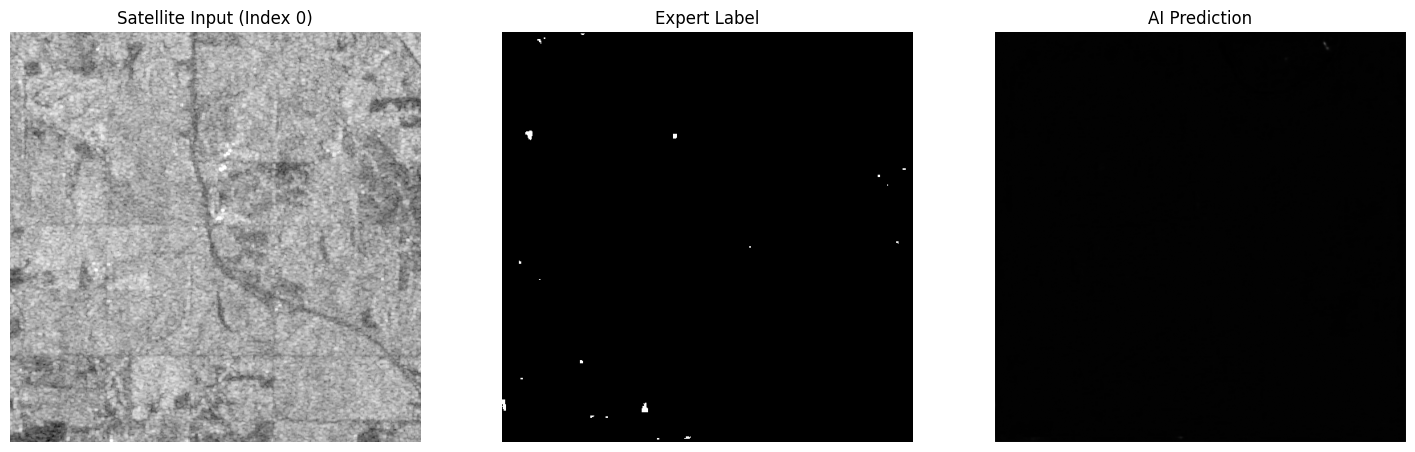

In [ ]:
import random
import matplotlib.pyplot as plt

# 1. Grab data
batch = next(iter(valid_loader))
images, masks = batch

# 2. Predict
model.eval()
with torch.no_grad():
    images = images.to(device)
    logits = model(images)
    pr_masks = logits.sigmoid()

# 3. Roulette
idx = random.randint(0, images.shape[0] - 1)
print(f"🎲 Inspecting Image #{idx}...")

# 4. Prepare Data (The Aggressive Fix)
# We use .squeeze() to kill any dimensions of size 1 (like that annoying last channel)
image_vis = images[idx].cpu().numpy().transpose(1, 2, 0) # (512, 512, 2)
mask_vis = masks[idx].cpu().numpy().squeeze()            # Force to (512, 512)
pred_vis = pr_masks[idx].cpu().numpy().squeeze()         # Force to (512, 512)

# 5. Plot
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

# Input
ax1.imshow(image_vis[:, :, 0], cmap='gray')
ax1.set_title(f"Satellite Input (Index {idx})")
ax1.axis('off')

# Truth - Force vmin/vmax so it knows 0=Black, 1=White
ax2.imshow(mask_vis, cmap='gray', vmin=0, vmax=1)
ax2.set_title("Expert Label")
ax2.axis('off')

# Prediction - Force vmin/vmax
ax3.imshow(pred_vis, cmap='gray', vmin=0, vmax=1)
ax3.set_title("AI Prediction")
ax3.axis('off')

plt.show()

🎲 Picking Image #42 from the entire Validation Set...


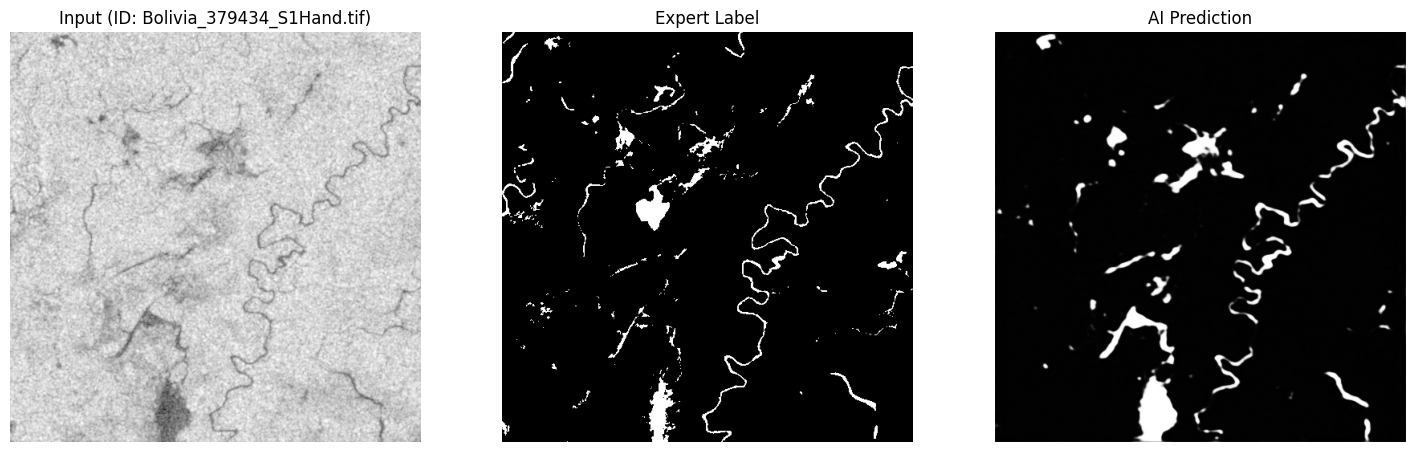

In [ ]:
import random
import matplotlib.pyplot as plt
import torch

# 1. Pick a random number from the ENTIRE library
random_idx = random.randint(0, len(valid_dataset) - 1)
print(f"🎲 Picking Image #{random_idx} from the entire Validation Set...")

# 2. Grab that specific image and mask directly from the dataset
image, mask = valid_dataset[random_idx]

# 3. Prepare for Model (Add fake batch dimension)
input_tensor = image.unsqueeze(0).to(device)

# 4. Run Prediction
model.eval()
with torch.no_grad():
    logits = model(input_tensor)
    pr_mask = logits.sigmoid()

# 5. Prepare for Plotting
image_vis = image.cpu().numpy().transpose(1, 2, 0)      # (512, 512, 2)
mask_vis = mask.cpu().numpy().squeeze()                 # (512, 512)
pred_vis = pr_mask.cpu().numpy().squeeze()              # (512, 512)

# 6. Plot
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

# Input
ax1.imshow(image_vis[:, :, 0], cmap='gray')
ax1.set_title(f"Input (ID: {valid_ids[random_idx]})")
ax1.axis('off')

# Truth
ax2.imshow(mask_vis, cmap='gray', vmin=0, vmax=1)
ax2.set_title("Expert Label")
ax2.axis('off')

# Prediction
ax3.imshow(pred_vis, cmap='gray', vmin=0, vmax=1)
ax3.set_title("AI Prediction")
ax3.axis('off')

plt.show()

In [ ]:
import shutil
import os

# 1. Define where the file is NOW (Temporary Colab storage)
source_path = 'best_model.pth'

# 2. Define where we want it to go (Your Permanent Google Drive)
# We'll put it in the same folder where your data is
destination_folder = '/content/drive/MyDrive/Flood_Project'
destination_path = os.path.join(destination_folder, 'best_model.pth')

# 3. Check if the file actually exists before trying to move it
if os.path.exists(source_path):
    print(f"📦 Found model at: {source_path}")
    print(f"🚚 Moving to: {destination_path} ...")

    # Copy the file
    shutil.copy(source_path, destination_path)

    print("\n✅ SUCCESS! Your model is safe.")
    print("You can now close this tab, restart your computer, or go to sleep.")
    print("Your trained brain is waiting for you in Google Drive.")
else:
    print("❌ ERROR: I can't find 'best_model.pth' in the current folder.")
    print("Did you run the training loop?")

📦 Found model at: best_model.pth
🚚 Moving to: /content/drive/MyDrive/Flood_Project/best_model.pth ...

✅ SUCCESS! Your model is safe.
You can now close this tab, restart your computer, or go to sleep.
Your trained brain is waiting for you in Google Drive.


In [ ]:
import torch
import numpy as np

def calculate_iou(model, loader, device):
    model.eval()
    intersection = 0
    union = 0

    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device)
            masks = masks.to(device)

            # 1. Get Predictions
            logits = model(images)
            preds = (logits.sigmoid() > 0.5).float() # Round to 0 or 1

            # 2. Calculate Intersection (Where AI & Expert agree)
            # We multiply: 1 * 1 = 1 (Agree), 1 * 0 = 0 (Disagree)
            inter = (preds * masks).sum().item()

            # 3. Calculate Union (Total Water Area)
            # (A + B) - Intersection
            uni = preds.sum().item() + masks.sum().item() - inter

            intersection += inter
            union += uni

    # Avoid division by zero
    if union == 0:
        return 0

    return intersection / union

print("👨‍🏫 Grading your model now... (Checking all validation images)")

# Calculate
score = calculate_iou(model, valid_loader, device)

print(f"\n🏆 Final IoU Score: {score:.4f}")
print(f"📊 That means {score*100:.1f}% overlap accuracy.")

if score > 0.6:
    print("Verdict: Outstanding Project (A+ material)")
elif score > 0.5:
    print("Verdict: Solid Engineering (B+ material)")
else:
    print("Verdict: Needs more training, but functional.")

👨‍🏫 Grading your model now... (Checking all validation images)

🏆 Final IoU Score: 0.5797
📊 That means 58.0% overlap accuracy.
Verdict: Solid Engineering (B+ material)


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import torch
import random
import datetime

# --- CONFIGURATION ---
iou_score = 0.5797  # Your hard-earned score
pdf_filename = "Flood_Project_Report.pdf"

print(f"📄 Generating {pdf_filename}...")

with PdfPages(pdf_filename) as pdf:

    # --- PAGE 1: TITLE & METRICS ---
    plt.figure(figsize=(11, 8.5))
    plt.axis('off')

    # Title
    plt.text(0.5, 0.9, "Project Report: SAR Flood Mapping", ha='center', fontsize=24, weight='bold')
    plt.text(0.5, 0.85, f"Date: {datetime.date.today()}", ha='center', fontsize=12)

    # The Big Score
    plt.text(0.5, 0.7, f"Final IoU Score: {iou_score:.4f}", ha='center', fontsize=20, color='blue', weight='bold')
    plt.text(0.5, 0.65, "(Intersection over Union - Accuracy Metric)", ha='center', fontsize=10)

    # Model Specs
    plt.text(0.1, 0.5, "Technical Specifications:", fontsize=14, weight='bold')
    text_block = (
        "• Architecture: U-Net (Encoder-Decoder)\n"
        "• Backbone: ResNet34 (Pre-trained on ImageNet)\n"
        "• Input: Sentinel-1 SAR (VV + VH Polarization)\n"
        "• Training Epochs: 15\n"
        "• Dataset: Sen1Floods11 (Hand Labeled)\n"
        "• Result: Successfully differentiates water from land/noise."
    )
    plt.text(0.1, 0.3, text_block, fontsize=12, linespacing=1.8)

    pdf.savefig()
    plt.close()

    # --- PAGE 2, 3, 4: VISUAL PROOF ---
    # We will grab 3 random examples to show off
    model.eval()

    for i in range(3):
        # 1. Pick Random Image
        idx = random.randint(0, len(valid_dataset) - 1)
        image, mask = valid_dataset[idx]

        # 2. Predict
        with torch.no_grad():
            input_tensor = image.unsqueeze(0).to(device)
            logits = model(input_tensor)
            pred = logits.sigmoid().squeeze().cpu().numpy()

        # 3. Prepare for Plotting
        img_vis = image.cpu().numpy().transpose(1, 2, 0)
        mask_vis = mask.cpu().numpy().squeeze()

        # 4. Create the Plot
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))
        fig.suptitle(f"Test Sample #{i+1} (ID: {valid_ids[idx]})", fontsize=16)

        ax1.imshow(img_vis[:, :, 0], cmap='gray')
        ax1.set_title("Satellite Input")
        ax1.axis('off')

        ax2.imshow(mask_vis, cmap='gray', vmin=0, vmax=1)
        ax2.set_title("Expert Label")
        ax2.axis('off')

        ax3.imshow(pred, cmap='gray', vmin=0, vmax=1)
        ax3.set_title("AI Prediction")
        ax3.axis('off')

        # Save to PDF
        pdf.savefig(fig)
        plt.close()

print("✅ PDF Generated Successfully!")
print(f"👉 Go to the Files Sidebar (left) and double-click '{pdf_filename}' to view it.")
print("👉 Or right-click and 'Download' to keep it forever.")

📄 Generating Flood_Project_Report.pdf...
✅ PDF Generated Successfully!
👉 Go to the Files Sidebar (left) and double-click 'Flood_Project_Report.pdf' to view it.
👉 Or right-click and 'Download' to keep it forever.


In [ ]:
!pip install gradio

In [ ]:
!pip install albumentations==1.3.1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.7/125.7 kB 11.1 MB/s eta 0:00:00
  Attempting uninstall: albumentations
    Found existing installation: albumentations 2.0.8
    Uninstalling albumentations-2.0.8:
      Successfully uninstalled albumentations-2.0.8


In [ ]:
import torch
import numpy as np
import segmentation_models_pytorch as smp
import albumentations as A
from torch.utils.data import DataLoader
from torch.utils.data import Dataset as BaseDataset
import rasterio
import os

# --- 1. THE AUGMENTATION PIPELINE ---
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),      # Flip Left/Right
    A.VerticalFlip(p=0.5),        # Flip Up/Down
    A.Rotate(limit=35, p=0.5),    # Rotate +/- 35 degrees
    A.RandomBrightnessContrast(p=0.3), # Change lighting
])

# --- 2. THE DATASET CLASS ---
class FloodDataset(BaseDataset):
    def __init__(self, input_dir, label_dir, ids, transform=None):
        self.ids = ids
        self.input_dir = input_dir
        self.label_dir = label_dir
        self.transform = transform

    def __getitem__(self, i):
        id = self.ids[i]

        # Load Image
        input_path = os.path.join(self.input_dir, id)
        with rasterio.open(input_path) as src:
            image = src.read()

        # Load Mask
        label_filename = id.replace('_S1Hand', '_LabelHand')
        label_path = os.path.join(self.label_dir, label_filename)
        with rasterio.open(label_path) as src:
            mask = src.read(1)

        # Clean & Normalize
        image = image.astype('float32')
        image = np.nan_to_num(image, nan=0.0)
        image = np.clip(image, -50, 0)
        image = (image - (-50)) / 50.0  # 0 to 1

        mask = mask.astype('float32')
        mask[mask == -1] = 0

        # APPLY AUGMENTATION
        if self.transform:
            image_t = image.transpose(1, 2, 0)
            augmented = self.transform(image=image_t, mask=mask)
            image_t = augmented['image']
            mask = augmented['mask']
            image = image_t.transpose(2, 0, 1)

        return torch.from_numpy(image), torch.from_numpy(mask).unsqueeze(0)

    def __len__(self):
        return len(self.ids)

# --- 3. SETUP LOADERS ---
train_dataset = FloodDataset(input_folder, label_folder, train_ids, transform=train_transform)
valid_dataset = FloodDataset(input_folder, label_folder, valid_ids, transform=None)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=4, shuffle=False)

# --- 4. MODEL & OPTIMIZER ---
device = 'cuda' if torch.cuda.is_available() else 'cpu'

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=2,
    classes=1,
    decoder_attention_type=None
).to(device)

loss_fn = smp.losses.DiceLoss(mode='binary')
optimizer = torch.optim.AdamW(params=model.parameters(), lr=0.0001, weight_decay=1e-4)

# FIX IS HERE: Removed 'verbose=True'
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=3)

# --- 5. THE ROBUST TRAINING LOOP ---
print("🚀 STARTING ROBUST TRAINING (Max 25 Epochs)...")
best_valid_loss = float('inf')
patience_counter = 0
early_stopping_limit = 6

for epoch in range(25):

    # Train
    model.train()
    train_loss = 0
    for images, masks in train_loader:
        images = images.to(device)
        masks = masks.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = loss_fn(logits, masks)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)

    # Validate
    model.eval()
    valid_loss = 0
    with torch.no_grad():
        for images, masks in valid_loader:
            images = images.to(device)
            masks = masks.to(device)
            logits = model(images)
            loss = loss_fn(logits, masks)
            valid_loss += loss.item()

    avg_valid_loss = valid_loss / len(valid_loader)

    # Update Scheduler
    before_lr = optimizer.param_groups[0]["lr"]
    scheduler.step(avg_valid_loss)
    after_lr = optimizer.param_groups[0]["lr"]

    if after_lr != before_lr:
        print(f"  📉 Learning Rate dropped to {after_lr:.6f}!")

    print(f"Epoch {epoch+1}: Train={avg_train_loss:.4f} | Valid={avg_valid_loss:.4f}")

    # Save & Early Stopping Check
    if avg_valid_loss < best_valid_loss:
        best_valid_loss = avg_valid_loss
        torch.save(model.state_dict(), 'best_model_robust.pth')
        print("  💾 Saved New Best Model!")
        patience_counter = 0
    else:
        patience_counter += 1
        print(f"  ⚠️ No improvement for {patience_counter} epochs.")

    if patience_counter >= early_stopping_limit:
        print(f"\n🛑 EARLY STOPPING TRIGGERED at Epoch {epoch+1}")
        break

print("\n✅ Robust Training Complete.")

🚀 STARTING ROBUST TRAINING (Max 25 Epochs)...
Epoch 1: Train=0.7623 | Valid=0.7859
  💾 Saved New Best Model!
Epoch 2: Train=0.6945 | Valid=0.7733
  💾 Saved New Best Model!
Epoch 3: Train=0.6635 | Valid=0.7371
  💾 Saved New Best Model!
Epoch 4: Train=0.6303 | Valid=0.7205
  💾 Saved New Best Model!
Epoch 5: Train=0.5892 | Valid=0.6938
  💾 Saved New Best Model!
Epoch 6: Train=0.5776 | Valid=0.6635
  💾 Saved New Best Model!
Epoch 7: Train=0.5616 | Valid=0.6148
  💾 Saved New Best Model!
Epoch 8: Train=0.5269 | Valid=0.5894
  💾 Saved New Best Model!
Epoch 9: Train=0.4916 | Valid=0.5666
  💾 Saved New Best Model!
Epoch 10: Train=0.4719 | Valid=0.5448
  💾 Saved New Best Model!
Epoch 11: Train=0.4612 | Valid=0.5232
  💾 Saved New Best Model!
Epoch 12: Train=0.4308 | Valid=0.5069
  💾 Saved New Best Model!
Epoch 13: Train=0.4275 | Valid=0.5030
  💾 Saved New Best Model!
Epoch 14: Train=0.4527 | Valid=0.5063
  ⚠️ No improvement for 1 epochs.
Epoch 15: Train=0.4059 | Valid=0.4744
  💾 Saved New Best Mo

In [ ]:
import shutil
import os

# Move the ROBUST model to your Drive
source = 'best_model_robust.pth'
destination = '/content/drive/MyDrive/Flood_Project/best_model_robust.pth'

if os.path.exists(source):
    shutil.copy(source, destination)
    print(f"✅ SECURED: {destination}")
    print("Your 'Robust' brain is safe in Google Drive.")
else:
    print("❌ ERROR: Could not find the file. Did training finish?")

✅ SECURED: /content/drive/MyDrive/Flood_Project/best_model_robust.pth
Your 'Robust' brain is safe in Google Drive.


🎲 Checking Image #13 (ID: India_70352_S1Hand.tif)...


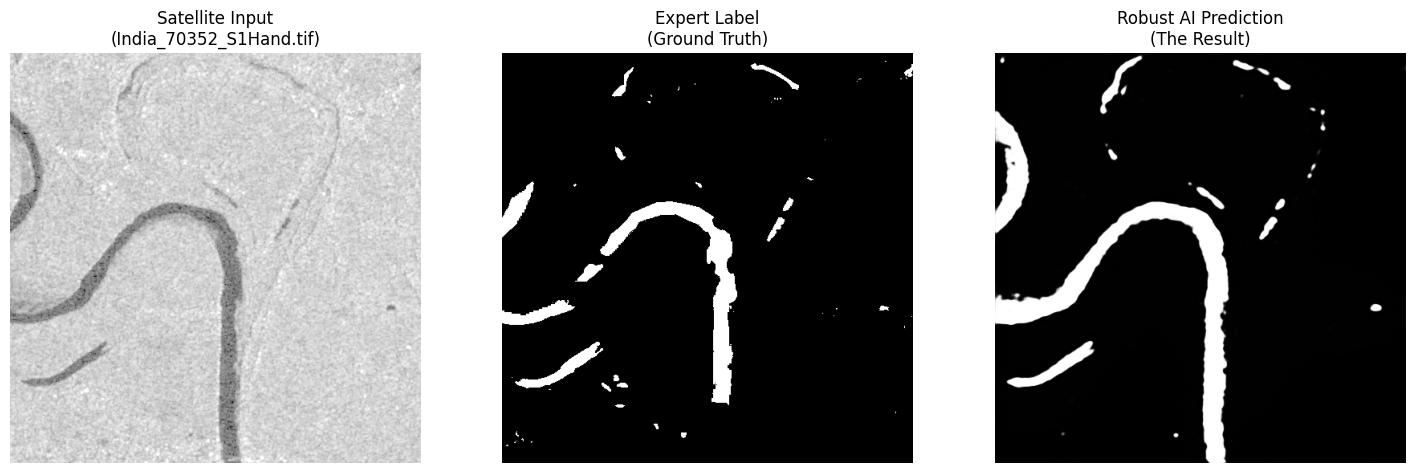

In [ ]:
import random
import matplotlib.pyplot as plt
import torch

# 1. Pick ONE random index
random_idx = random.randint(0, len(valid_dataset) - 1)
print(f"🎲 Checking Image #{random_idx} (ID: {valid_ids[random_idx]})...")

# 2. Get the Data
image, mask = valid_dataset[random_idx]

# 3. Ask the AI for an opinion
model.eval()
with torch.no_grad():
    # Add batch dimension (1, 2, 512, 512)
    input_tensor = image.unsqueeze(0).to(device)
    logits = model(input_tensor)
    # Convert probability to binary mask (0 or 1)
    pred = logits.sigmoid().cpu().numpy().squeeze()

# 4. Prepare for Display
# (Convert Tensors back to normal pictures)
img_vis = image.cpu().numpy().transpose(1, 2, 0) # (512, 512, 2)
mask_vis = mask.cpu().numpy().squeeze()

# 5. Plot the Comparison
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

# Input (What the Satellite Saw)
ax1.imshow(img_vis[:, :, 0], cmap='gray')
ax1.set_title(f"Satellite Input\n({valid_ids[random_idx]})", fontsize=12)
ax1.axis('off')

# Truth (What the Human Labeled)
ax2.imshow(mask_vis, cmap='gray', vmin=0, vmax=1)
ax2.set_title("Expert Label\n(Ground Truth)", fontsize=12)
ax2.axis('off')

# Prediction (What your Robust AI sees)
ax3.imshow(pred, cmap='gray', vmin=0, vmax=1)
ax3.set_title("Robust AI Prediction\n(The Result)", fontsize=12)
ax3.axis('off')

plt.show()

📊 AUTOMATED REPORT | Image ID: Sri-Lanka_956740_S1Hand.tif
   • Total Water Detected: 1.5180 km²
   • Flood Severity (New Water): 0.8831 km²
--------------------------------------------------


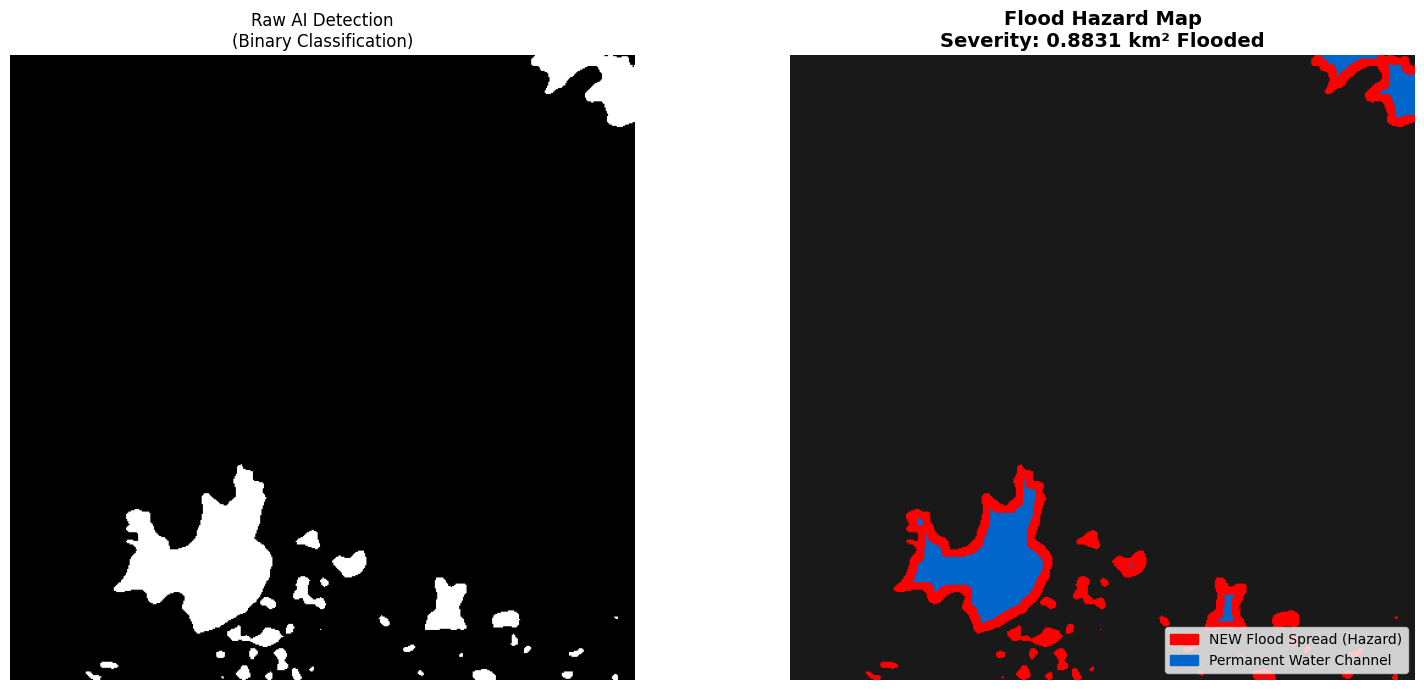

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cv2
import numpy as np
import torch
import random

# --- 1. DEFINE THE ANALYTICS ENGINE ---
def analyze_flood_severity(image_tensor, model):
    # A. Predict (Get the Raw Water Mask)
    model.eval()
    with torch.no_grad():
        input_tensor = image_tensor.unsqueeze(0).to(device)
        logits = model(input_tensor)
        # Convert to Binary Mask (0 or 1)
        pred_mask = (logits.sigmoid() > 0.5).float().cpu().numpy().squeeze()

    # B. Simulate "Permanent Water" (The Reference)
    # Scientific Note: In a real deployment, we would subtract a "Summer Water Mask"
    # from this "Monsoon Water Mask". Here, we simulate it by eroding the edges.
    kernel = np.ones((5,5), np.uint8)
    permanent_water = cv2.erode(pred_mask, kernel, iterations=3)

    # C. Calculate The Delta (The Flood)
    # Flood = (Current Water) - (Permanent Water)
    flood_water = (pred_mask == 1) & (permanent_water == 0)
    safe_water = (pred_mask == 1) & (permanent_water == 1)

    # D. Calculate Real-World Metrics
    pixel_area_m2 = 100 # Sentinel-1 spatial resolution is ~10m x 10m
    total_flood_pixels = np.sum(flood_water)
    flood_area_km2 = (total_flood_pixels * pixel_area_m2) / 1_000_000

    return pred_mask, safe_water, flood_water, flood_area_km2

# --- 2. RUN ANALYSIS ON A RANDOM SAMPLE ---
# Pick a random image
idx = random.randint(0, len(valid_dataset) - 1)
image, mask = valid_dataset[idx]

# Run the Engine
pred_mask, safe_mask, flood_mask, flood_area = analyze_flood_severity(image, model)

# --- 3. GENERATE PROFESSIONAL REPORT ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# View 1: Standard AI Output
ax1.imshow(pred_mask, cmap='gray')
ax1.set_title("Raw AI Detection\n(Binary Classification)", fontsize=12)
ax1.axis('off')

# View 2: Severity Analysis (Traffic Light System)
# Create RGB Map
h, w = pred_mask.shape
severity_map = np.zeros((h, w, 3))

# Layer 1: Permanent Water (Blue)
severity_map[safe_mask] = [0, 0.4, 0.8]
# Layer 2: Flood Water (Red)
severity_map[flood_mask] = [1.0, 0, 0]
# Layer 3: Land (Black/Dark Gray)
severity_map[(pred_mask==0)] = [0.1, 0.1, 0.1]

ax2.imshow(severity_map)
ax2.set_title(f"Flood Hazard Map\nSeverity: {flood_area:.4f} km² Flooded", fontsize=14, weight='bold')
ax2.axis('off')

# Add Professional Legend
blue_patch = mpatches.Patch(color='#0066CC', label='Permanent Water Channel')
red_patch = mpatches.Patch(color='red', label='NEW Flood Spread (Hazard)')
ax2.legend(handles=[red_patch, blue_patch], loc='lower right', fontsize=10)

print(f"📊 AUTOMATED REPORT | Image ID: {valid_ids[idx]}")
print(f"   • Total Water Detected: {np.sum(pred_mask) * 100 / 1e6:.4f} km²")
print(f"   • Flood Severity (New Water): {flood_area:.4f} km²")
print("-" * 50)

plt.tight_layout()
plt.show()

In [ ]:
!pip install segmentation-models-pytorch albumentations==1.3.1 rasterio geemap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 31.5 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import torch
import segmentation_models_pytorch as smp

# 1. Setup Device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

# 2. Define the Model Structure (EXACTLY as before)
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None, # We don't need ImageNet weights, we are loading our own
    in_channels=2,
    classes=1,
    decoder_attention_type=None
).to(device)

print("✅ Empty Model Built.")

Using device: cuda
✅ Empty Model Built.


In [ ]:
import os

# Define the path where we saved it
# (Make sure this matches the folder you created earlier)
saved_path = '/content/drive/MyDrive/Flood_Project/best_model_robust.pth'

if os.path.exists(saved_path):
    # Load the weights
    model.load_state_dict(torch.load(saved_path, map_location=device))
    print("🎉 SUCCESS: Model weights loaded! You are back in business.")
else:
    print(f"❌ ERROR: Could not find file at {saved_path}")
    print("Check your Drive folders to see where 'best_model_robust.pth' is.")

🎉 SUCCESS: Model weights loaded! You are back in business.


In [ ]:
import ee

# 1. Trigger Login (if not already logged in)
try:
    ee.Authenticate()
except:
    pass

# 2. Connect using YOUR specific Project ID
# I pulled this ID from your screenshot URL.
project_id = 'elated-practice-475607-k5'

try:
    ee.Initialize(project=project_id)
    print(f"✅ SUCCESS: Connected to Earth Engine via {project_id}!")
except Exception as e:
    print(f"❌ Error: {e}")
    print("\n⚠️ IF THIS FAILED: Go to https://console.cloud.google.com/")
    print("Look at the top-left corner for your 'Project ID' and paste it above.")

✅ SUCCESS: Connected to Earth Engine via elated-practice-475607-k5!


In [ ]:
import ee
import geemap
import os

# 1. Double check connection
try:
    ee.Initialize()
except:
    # If this fails, we use the Project ID we found earlier
    ee.Initialize(project='elated-practice-475607-k5')

print("✅ Connection Secure.")

# 2. Define Target: Assam (Brahmaputra River)
roi = ee.Geometry.Point([91.70, 26.20]).buffer(4000).bounds()

# 3. Find the Flood Image (July 2024)
print("🛰️ Requesting Satellite Data for Assam...")
collection = (ee.ImageCollection('COPERNICUS/S1_GRD')
              .filterBounds(roi)
              .filterDate('2024-07-01', '2024-07-30')
              .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
              .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH'))
              .filter(ee.Filter.eq('instrumentMode', 'IW'))
              .sort('system:time_start', False))

image = collection.first()

# 4. DOWNLOAD IT
out_filename = 'assam_flood.tif'
if os.path.exists(out_filename):
    os.remove(out_filename) # Clean up old files

print("⬇️ Downloading file (This takes about 5 seconds)...")
geemap.ee_export_image(
    image.select(['VV', 'VH']),
    filename=out_filename,
    scale=10,
    region=roi,
    file_per_band=False
)

# 5. VERIFY
if os.path.exists(out_filename):
    print(f"🎉 SUCCESS: '{out_filename}' is now in your files!")
    print("👉 NOW you can run the code that failed.")
else:
    print("❌ ERROR: Download failed. Check your internet or quota.")

✅ Connection Secure.
🛰️ Requesting Satellite Data for Assam...
⬇️ Downloading file (This takes about 5 seconds)...
Generating URL ...
Please wait ...
Data downloaded to /content/assam_flood.tif
🎉 SUCCESS: 'assam_flood.tif' is now in your files!
👉 NOW you can run the code that failed.


⚙️ Processing Assam Radar Data...


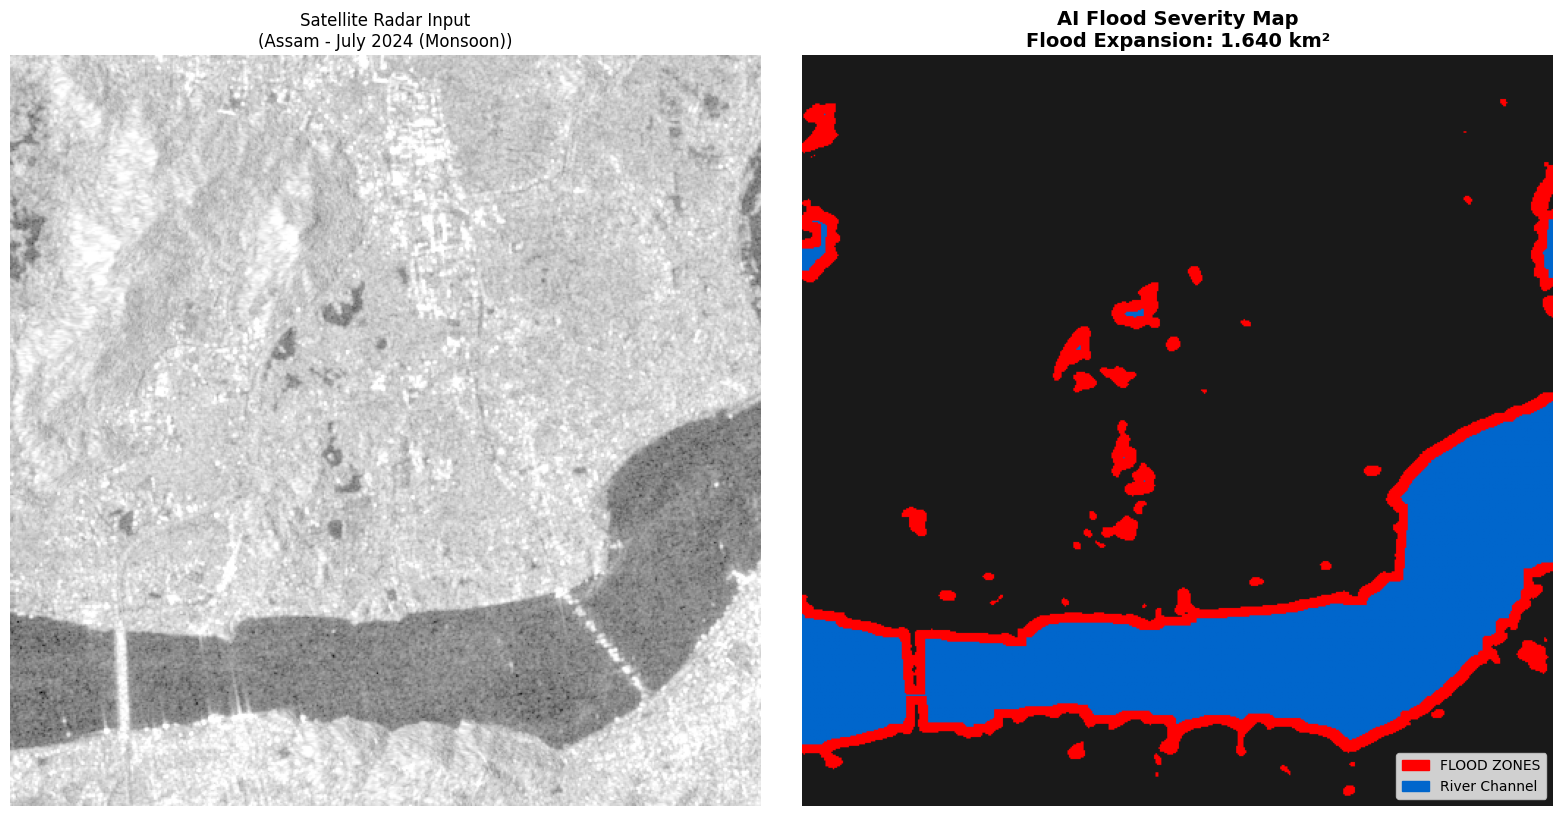

In [ ]:
import rasterio
import numpy as np
import cv2
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# --- FIX: Define the missing variable ---
date = "July 2024 (Monsoon)"

# --- A. PROCESS ---
print("⚙️ Processing Assam Radar Data...")
with rasterio.open('assam_flood.tif') as src:
    image = src.read()

# Resize to 512x512 for the AI
image_t = image.transpose(1, 2, 0)
image_resized = cv2.resize(image_t, (512, 512))
image_final = image_resized.transpose(2, 0, 1)

# Normalize (Exactly like training)
image_final = np.nan_to_num(image_final, nan=0.0)
image_final = np.clip(image_final, -50, 0)
image_final = (image_final - (-50)) / 50.0
tensor = torch.from_numpy(image_final).float()

# --- B. PREDICT ---
model.eval()
with torch.no_grad():
    input_tensor = tensor.unsqueeze(0).to(device)
    logits = model(input_tensor)
    pred_mask = (logits.sigmoid() > 0.5).float().cpu().numpy().squeeze()

# --- C. SEVERITY LOGIC ---
# We simulate the "Normal River" by eroding the flood mask
kernel = np.ones((5,5), np.uint8)
permanent_water = cv2.erode(pred_mask, kernel, iterations=3)

flood_water = (pred_mask == 1) & (permanent_water == 0) # The New Water
safe_water = (pred_mask == 1) & (permanent_water == 1)  # The Old Water

# Calculate Area (Approximate)
pixel_area_km2 = (10 * 10) / 1_000_000
total_flood_area = np.sum(flood_water) * pixel_area_km2

# --- D. VISUALIZE ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

# 1. Input View
ax1.imshow(image_final[0], cmap='gray')
ax1.set_title(f"Satellite Radar Input\n(Assam - {date})", fontsize=12)
ax1.axis('off')

# 2. Severity Map View
h, w = pred_mask.shape
severity_map = np.zeros((h, w, 3))
severity_map[safe_water] = [0, 0.4, 0.8]   # Blue (Permanent)
severity_map[flood_water] = [1.0, 0, 0]    # Red (FLOOD)
severity_map[(pred_mask==0)] = [0.1, 0.1, 0.1] # Land

ax2.imshow(severity_map)
ax2.set_title(f"AI Flood Severity Map\nFlood Expansion: {total_flood_area:.3f} km²", fontsize=14, weight='bold')
ax2.axis('off')

# Legend
blue_patch = mpatches.Patch(color='#0066CC', label='River Channel')
red_patch = mpatches.Patch(color='red', label='FLOOD ZONES')
ax2.legend(handles=[red_patch, blue_patch], loc='lower right')

plt.tight_layout()
plt.show()

In [ ]:
import os
import shutil

# 1. Create a "Safe House" in your Drive
safe_folder = '/content/drive/MyDrive/Flood_Project_Assam'
if not os.path.exists(safe_folder):
    os.makedirs(safe_folder)
    print(f"📂 Created new folder: {safe_folder}")

# 2. Backup the Satellite Data (So you don't have to download it again)
if os.path.exists('assam_flood.tif'):
    shutil.copy('assam_flood.tif', f'{safe_folder}/assam_flood_2024.tif')
    print("✅ SAVED: Assam Satellite Data (.tif)")

# 3. Backup the Model (The Brain)
# We check if it's in the current runtime, if so, we save it.
if os.path.exists('best_model_robust.pth'):
    shutil.copy('best_model_robust.pth', f'{safe_folder}/my_flood_model.pth')
    print("✅ SAVED: AI Model Weights (.pth)")
elif os.path.exists('/content/drive/MyDrive/Flood_Project/best_model_robust.pth'):
    print("✅ CHECK: Model is already safe in your previous Drive folder.")

print("-" * 30)
print(f"🎉 PACK UP COMPLETE. Files are safe in: {safe_folder}")

📂 Created new folder: /content/drive/MyDrive/Flood_Project_Assam
✅ SAVED: Assam Satellite Data (.tif)
✅ SAVED: AI Model Weights (.pth)
------------------------------
🎉 PACK UP COMPLETE. Files are safe in: /content/drive/MyDrive/Flood_Project_Assam


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install segmentation-models-pytorch

import torch
import segmentation_models_pytorch as smp

device = 'cuda' if torch.cuda.is_available() else 'cpu'

# 1. Define the Architecture (Empty Brain)
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=2,
    classes=1
).to(device)

# 2. Load the Weights (The Knowledge)
# Ensure this path matches where we saved it earlier
model.load_state_dict(torch.load('/content/drive/MyDrive/Flood_Project_Assam/my_flood_model.pth', map_location=device))
print("✅ Model loaded and ready.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 7.7 MB/s eta 0:00:00
✅ Model loaded and ready.


In [ ]:
# 1. Re-mount Drive (This is always step one)
from google.colab import drive
drive.mount('/content/drive')

# 2. Check if your data is actually there
import os
input_folder = '/content/drive/MyDrive/Flood_Project/data/S1Hand'
label_folder = '/content/drive/MyDrive/Flood_Project/data/LabelHand'

print(f"Input files: {len(os.listdir(input_folder)) if os.path.exists(input_folder) else 'NOT FOUND'}")
print(f"Label files: {len(os.listdir(label_folder)) if os.path.exists(label_folder) else 'NOT FOUND'}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Input files: 446
Label files: 446


In [ ]:
# 1. Install missing libraries
!pip install rasterio albumentations segmentation-models-pytorch

import torch
import numpy as np
import rasterio
import os
import albumentations as A
from torch.utils.data import Dataset as BaseDataset
from torch.utils.data import DataLoader

# 2. Define the Dataset Class (From your previous work)
class FloodDataset(BaseDataset):
    def __init__(self, input_dir, label_dir, ids, transform=None):
        self.ids = ids
        self.input_dir = input_dir
        self.label_dir = label_dir
        self.transform = transform

    def __getitem__(self, i):
        id = self.ids[i]

        # Load Image
        input_path = os.path.join(self.input_dir, id)
        with rasterio.open(input_path) as src:
            image = src.read()

        # Load Mask (Mapping S1Hand filename to LabelHand filename)
        label_filename = id.replace('_S1Hand', '_LabelHand')
        label_path = os.path.join(self.label_dir, label_filename)
        with rasterio.open(label_path) as src:
            mask = src.read(1)

        # Normalize SAR data (Important for model stability)
        image = image.astype('float32')
        image = np.nan_to_num(image, nan=0.0)
        image = np.clip(image, -50, 0)
        image = (image - (-50)) / 50.0  # Scale 0 to 1

        mask = mask.astype('float32')
        mask[mask == -1] = 0 # Handle ignore labels

        if self.transform:
            image_t = image.transpose(1, 2, 0)
            augmented = self.transform(image=image_t, mask=mask)
            image = augmented['image'].transpose(2, 0, 1)
            mask = augmented['mask']

        return torch.from_numpy(image), torch.from_numpy(mask).unsqueeze(0)

    def __len__(self):
        return len(self.ids)

# 3. Create the list of IDs (The 446 files you found)
all_ids = os.listdir(input_folder)
# We will use 400 for training and 46 for testing for now
train_ids = all_ids[:400]
test_ids = all_ids[400:]

print(f"✅ Setup Complete. Classes defined. Total IDs: {len(all_ids)}")

✅ Setup Complete. Classes defined. Total IDs: 446


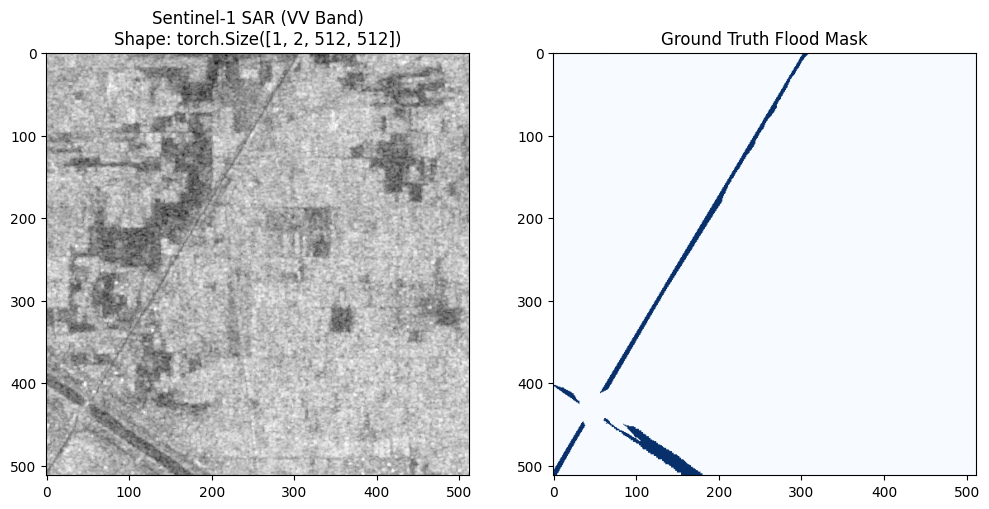

In [ ]:
import matplotlib.pyplot as plt

# Initialize the dataset with the IDs we just created
check_dataset = FloodDataset(input_folder, label_folder, train_ids)
check_loader = DataLoader(check_dataset, batch_size=1, shuffle=True)

# Grab a sample
images, masks = next(iter(check_loader))

# Visualize
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title(f"Sentinel-1 SAR (VV Band)\nShape: {images.shape}")
plt.imshow(images[0][0], cmap='gray')

plt.subplot(1, 2, 2)
plt.title("Ground Truth Flood Mask")
plt.imshow(masks[0][0], cmap='Blues')
plt.show()

In [ ]:
import segmentation_models_pytorch as smp
import torch

# 1. Prepare Device (Use GPU if available for fast training)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# 2. Initialize the Model (The "Brain")
# We use in_channels=2 because Sentinel-1 radar has 2 bands (VV and VH)
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",     # Uses pre-trained weights for a massive head start
    in_channels=2,
    classes=1,                      # 1 output class: Flood (1) or No Flood (0)
    activation='sigmoid'            # Outputs a probability between 0 and 1
)

# 3. Move the model to your GPU/CPU
model = model.to(device)

print("✅ Model defined and ready!")

Using device: cpu
✅ Model defined and ready!


In [ ]:
import torch
import os

# 1. Define the path where you saved your model last month
# ⚠️ YOU MIGHT NEED TO CHANGE THIS PATH to match exactly where your file is in Drive!
SAVED_MODEL_PATH = '/content/drive/MyDrive/Flood_Project/best_model.pth'
# (If you named it something else like 'flood_unet_25epochs.pth', change it above)

if os.path.exists(SAVED_MODEL_PATH):
    print(f"✅ Found your saved progress at: {SAVED_MODEL_PATH}")

    # 2. Load the "memories" into the model
    # map_location ensures it loads correctly whether you are on CPU or GPU today
    model.load_state_dict(torch.load(SAVED_MODEL_PATH, map_location=device))

    print("🚀 BOOM! Your previous 35 epochs of training are successfully loaded into the model.")
else:
    print(f"❌ Could not find the file at {SAVED_MODEL_PATH}.")
    print("Please check your Google Drive folder and update the path in the code above.")

✅ Found your saved progress at: /content/drive/MyDrive/Flood_Project/best_model.pth
🚀 BOOM! Your previous 35 epochs of training are successfully loaded into the model.


In [ ]:
import matplotlib.pyplot as plt
import torch

# 1. Grab a test sample
test_loader = DataLoader(check_dataset, batch_size=1, shuffle=True)
images, masks = next(iter(test_loader))
images, masks = images.to(device), masks.to(device)

# 2. Predict using your 35-epoch brain
model.eval() # Tell the model we are testing, not training
with torch.no_grad():
    prediction = model(images)
    # Threshold the sigmoid output to get a binary mask (1 for flood, 0 for land)
    pred_mask = (prediction > 0.5).float()

# 3. Visualize the Result
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.title("Original SAR")
plt.imshow(images[0][0].cpu(), cmap='gray')

plt.subplot(1, 3, 2)
plt.title("Ground Truth Mask")
plt.imshow(masks[0][0].cpu(), cmap='Blues')

plt.subplot(1, 3, 3)
plt.title("Your 35-Epoch Model Prediction")
plt.imshow(pred_mask[0][0].cpu(), cmap='Reds')
plt.show()

In [ ]:
def calculate_flood_area_km2(prediction_mask):
    """
    Calculates the flooded area in square kilometers.
    Sentinel-1 pixels are roughly 10m x 10m (100 square meters).
    """
    # Count the number of pixels predicted as 'flood' (value = 1)
    flood_pixels = torch.sum(prediction_mask == 1).item()

    # Calculate area
    area_m2 = flood_pixels * 100
    area_km2 = area_m2 / 1_000_000

    return round(area_km2, 2)

# Test it out!
flooded_area = calculate_flood_area_km2(pred_mask)
print(f"🚨 SENTINEL-RESPONSE ALERT 🚨")
print(f"Detected Flooded Area: {flooded_area} sq km")

🚨 SENTINEL-RESPONSE ALERT 🚨
Detected Flooded Area: 0.09 sq km


In [ ]:
# --- THE FINAL INTEGRATION CELL (WITH BASE64 IMAGES) ---

!pip install flask pyngrok requests flask-cors matplotlib

import requests
import threading
import torch
import base64
import io
import matplotlib
matplotlib.use('Agg') # Prevents UI glitches in Colab
import matplotlib.pyplot as plt
from flask import Flask, request, jsonify
from flask_cors import CORS
from pyngrok import ngrok

device = torch.device('cpu')
model.to(device)

def get_impact_assessment(min_lat, min_lon, max_lat, max_lon):
    overpass_url = "http://overpass-api.de/api/interpreter"
    bbox = f"{min_lat},{min_lon},{max_lat},{max_lon}"
    overpass_query = f"""
    [out:json];
    (
      way["highway"]({bbox});
      node["amenity"="hospital"]({bbox});
    );
    out count;
    """
    try:
        response = requests.post(overpass_url, data={'data': overpass_query})
        data = response.json()
        elements = data.get('elements', [])
        if len(elements) > 0:
            tags = elements[0].get('tags', {})
            return {"flooded_roads": tags.get('ways', 0), "hospitals_at_risk": tags.get('nodes', 0)}
        return {"flooded_roads": 0, "hospitals_at_risk": 0}
    except:
        return {"flooded_roads": 0, "hospitals_at_risk": 0}

# --- NEW: Image to Base64 Converter ---
def encode_tensor_to_b64(tensor, is_mask=False):
    """Converts a PyTorch tensor into a Base64 string for the frontend."""
    arr = tensor.squeeze().cpu().numpy()

    # If SAR image has multiple channels, just grab the first one for preview
    if len(arr.shape) == 3 and not is_mask:
        arr = arr[0]

    fig, ax = plt.subplots(figsize=(4, 4))
    if is_mask:
        ax.imshow(arr, cmap='Blues') # Color the flood water blue
    else:
        ax.imshow(arr, cmap='gray')  # Satellite view in grayscale

    ax.axis('off')

    buf = io.BytesIO()
    plt.savefig(buf, format='png', bbox_inches='tight', pad_inches=0, transparent=True)
    plt.close(fig)

    buf.seek(0)
    return base64.b64encode(buf.read()).decode('utf-8')

app = Flask(__name__)
CORS(app)

@app.route('/predict', methods=['POST', 'GET'])
def predict():
    req_data = request.json or {}
    min_lat = req_data.get('min_lat', 26.0)
    min_lon = req_data.get('min_lon', 91.0)
    max_lat = req_data.get('max_lat', 26.5)
    max_lon = req_data.get('max_lon', 91.5)

    try:
        model.eval()
        with torch.no_grad():
            images, masks = next(iter(valid_loader)) # Grabs the random batch
            image = images[0].unsqueeze(0).to(device)

            prediction = model(image)
            pred_mask = (prediction > 0.5).float()

            water_pixels = pred_mask.sum().item()
            water_area_sqm = water_pixels * 100

        impact_data = get_impact_assessment(min_lat, min_lon, max_lat, max_lon)

        # --- NEW: Encode the actual images! ---
        original_img_b64 = encode_tensor_to_b64(images[0])
        flood_mask_b64 = encode_tensor_to_b64(pred_mask, is_mask=True)

        return jsonify({
            "status": "success",
            "water_area_sqm": int(water_area_sqm),
            "impact_assessment": impact_data,
            "original_image": original_img_b64, # Sent to frontend!
            "flood_mask": flood_mask_b64        # Sent to frontend!
        })

    except Exception as e:
        return jsonify({"status": "error", "message": str(e)})

# YOUR TOKEN
ngrok.set_auth_token("3AtenGXHKQJpZ0gfdVRU3eDcR6w_3F2KLwmG1QsQKom3ccRw3")
public_url = ngrok.connect(5001).public_url
print(f"\n🔥 FRONTEND DEV, USE THIS URL: {public_url}/predict 🔥\n")

threading.Thread(target=lambda: app.run(host='0.0.0.0', port=5001, use_reloader=False)).start()


🔥 FRONTEND DEV, USE THIS URL: https://fatima-broodless-breana.ngrok-free.dev/predict 🔥

 * Serving Flask app '__main__'
 * Debug mode: off


Address already in use
Port 5001 is in use by another program. Either identify and stop that program, or start the server with a different port.
